# Comparação: Five-Spot e produtor central

Compara os dois modelos usando os mesmos parâmetros, malha, permeabilidade, pressão inicial e pressão prescrita no produtor. A diferença é calculada como pressão do Five-Spot menos pressão do produtor central.

Diferença final média assinada: 1.4371 MPa
Diferença final média absoluta: 1.4371 MPa
Diferença final máxima absoluta: 4.0861 MPa
Pressão central final - produtor central: 17.2115 MPa
Pressão central final - Five-Spot: 17.8309 MPa
Vazão final do produtor central: -3.096726e-02 m³/s
Vazão final do produtor Five-Spot: -3.964084e-02 m³/s


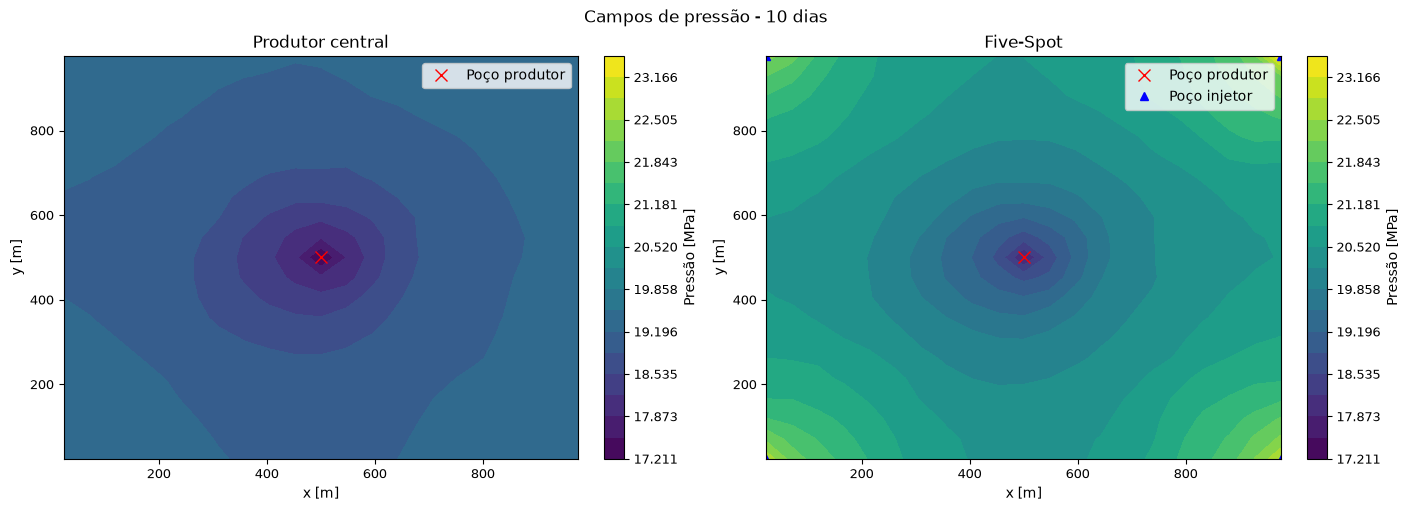

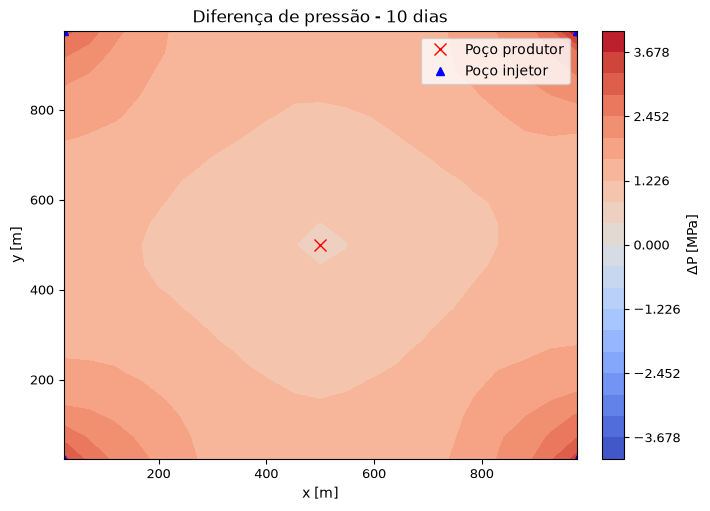

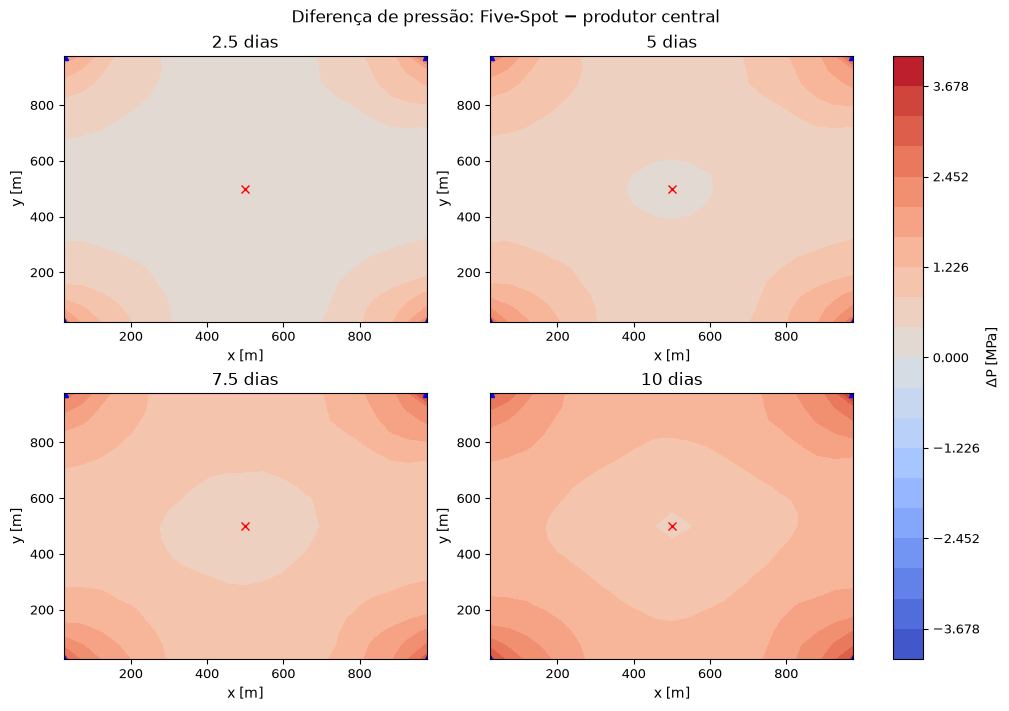

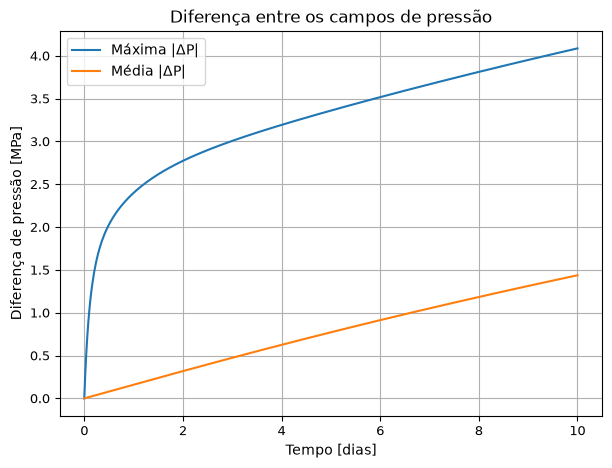

In [1]:
from pathlib import Path
import sys
ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 10, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})
from mdf.implicita_2d import implicita_2d
from mdf.permeabilidade2d import carregar_permeabilidade

p0 = 20.684e6
pwf = 15.0e6
q_injecao_total = 3.72e-2
Lx = Ly = 1000.0
h = 30.0
rw = 0.10
phi = 0.22
ct = 3.046e-9
mu = 1.0e-3
t_d = 10
t_final = t_d * 86400
nx = ny = 21
nt = 500
dx = Lx / nx
dy = Ly / ny
dt = t_final / nt
k_mD = carregar_permeabilidade(ROOT / "data" / "permeabilidade.csv")
k = k_mD * 9.869233e-16
iw = nx // 2
jw = ny // 2
x, y, t, P_central, q_central = implicita_2d(p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt, iw=iw, jw=jw)
injetores = [
    {"i": 0, "j": 0, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": 0, "rate": q_injecao_total / 4},
    {"i": 0, "j": ny - 1, "rate": q_injecao_total / 4},
    {"i": nx - 1, "j": ny - 1, "rate": q_injecao_total / 4},
]
x5, y5, t5, P_five_spot, q_five_spot = implicita_2d(p0, pwf, rw, h, Lx, Ly, k, phi, ct, mu, t_final, nx, ny, nt, iw=iw, jw=jw, injection_wells=injetores)
if not (np.array_equal(x, x5) and np.array_equal(y, y5) and np.array_equal(t, t5)):
    raise ValueError("As simulações não compartilham a mesma malha espacial e temporal")
delta_p = (P_five_spot - P_central) / 1e6
max_abs = np.max(np.abs(delta_p), axis=(1, 2))
mean_abs = np.mean(np.abs(delta_p), axis=(1, 2))
print(f"Diferença final média assinada: {np.mean(delta_p[-1]):.4f} MPa")
print(f"Diferença final média absoluta: {mean_abs[-1]:.4f} MPa")
print(f"Diferença final máxima absoluta: {max_abs[-1]:.4f} MPa")
print(f"Pressão central final - produtor central: {P_central[-1, jw, iw] / 1e6:.4f} MPa")
print(f"Pressão central final - Five-Spot: {P_five_spot[-1, jw, iw] / 1e6:.4f} MPa")
print(f"Vazão final do produtor central: {q_central[-1]:.6e} m³/s")
print(f"Vazão final do produtor Five-Spot: {q_five_spot[-1]:.6e} m³/s")
X, Y = np.meshgrid(x, y)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
levels_p = np.linspace(min(P_central[-1].min(), P_five_spot[-1].min()) / 1e6, max(P_central[-1].max(), P_five_spot[-1].max()) / 1e6, 20)
for ax, field, title_text in zip(axes, (P_central[-1], P_five_spot[-1]), ("Produtor central", "Five-Spot")):
    contour = ax.contourf(X, Y, field / 1e6, levels=levels_p, cmap="viridis")
    ax.set_title(title_text)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    fig.colorbar(contour, ax=ax, label="Pressão [MPa]")
axes[0].plot(x[iw], y[jw], "rx", markersize=8, label="Poço produtor")
axes[0].legend(loc="upper right")
axes[1].plot(x[iw], y[jw], "rx", markersize=8, label="Poço produtor")
for well in injetores:
    axes[1].plot(x[well["i"]], y[well["j"]], "b^", label="Poço injetor" if well is injetores[0] else None)
axes[1].legend(loc="upper right")
fig.suptitle("Campos de pressão - 10 dias")
fig.savefig(RESULTS_DIR / "comparacao_pressao_five_spot_produtor_central.pdf", dpi=180, bbox_inches="tight")
plt.show()

lim = np.max(np.abs(delta_p[-1]))
fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
contour = ax.contourf(X, Y, delta_p[-1], levels=np.linspace(-lim, lim, 21), cmap="coolwarm")
ax.plot(x[iw], y[jw], "rx", markersize=8, label="Poço produtor")
for well in injetores:
    ax.plot(x[well["i"]], y[well["j"]], "b^", label="Poço injetor" if well is injetores[0] else None)
ax.set_title("Diferença de pressão - 10 dias")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.legend(loc="upper right")
fig.colorbar(contour, ax=ax, label="ΔP [MPa]")
fig.savefig(RESULTS_DIR / "diferenca_pressao_five_spot_final.pdf", dpi=180, bbox_inches="tight")
plt.show()
indices = [int(np.argmin(np.abs(t - day * 86400))) for day in (2.5, 5, 7.5, 10)]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), constrained_layout=True)
lim = np.max(np.abs(delta_p[indices]))
for ax, index, day in zip(axes.flat, indices, (2.5, 5, 7.5, 10)):
    contour = ax.contourf(X, Y, delta_p[index], levels=np.linspace(-lim, lim, 21), cmap="coolwarm")
    for well in injetores:
        ax.plot(x[well["i"]], y[well["j"]], "b^")
    ax.plot(x[iw], y[jw], "rx")
    ax.set_title(f"{day:g} dias")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
fig.colorbar(contour, ax=axes.ravel().tolist(), label="ΔP [MPa]")
fig.suptitle("Diferença de pressão: Five-Spot − produtor central")
fig.savefig(RESULTS_DIR / "diferenca_pressao_five_spot_transiente.pdf", dpi=180, bbox_inches="tight")
plt.show()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(t / 86400, max_abs, label="Máxima |ΔP|")
ax.plot(t / 86400, mean_abs, label="Média |ΔP|")
ax.set_xlabel("Tempo [dias]")
ax.set_ylabel("Diferença de pressão [MPa]")
ax.set_title("Diferença entre os campos de pressão")
ax.grid()
ax.legend()
fig.savefig(RESULTS_DIR / "metricas_diferenca_pressao_five_spot.pdf", dpi=180, bbox_inches="tight")
plt.show()
